# Lab 6 : Covariance & Correlation
**Lakshay** : AP24110010677 : B.Tech CSE (AI/ML)

**Aim**
1. Compute the covariance and correlation between a **pair of attributes**.
2. Compute the **covariance matrix** and the **correlation matrix** of a dataset.

**Dataset** : Iris (150 flowers, 4 numeric attributes : sepal length, sepal width, petal length, petal width) loaded from scikit-learn. A tiny 5-row example is worked out by hand first so the formulas are clear.

## Theory

**Covariance** tells the *direction* in which two attributes move together.

$$\text{Cov}(X,Y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})$$

* Cov > 0 : X and Y increase together
* Cov < 0 : when one increases the other decreases
* Cov ≈ 0 : no linear relationship
* Its value depends on the units, so it cannot tell us how *strong* the relationship is.

**Pearson correlation** is covariance divided by both standard deviations, so it is unit-free and always lies in [-1, 1].

$$r_{XY} = \frac{\text{Cov}(X,Y)}{\sigma_X\,\sigma_Y}$$

* r = +1 : perfect positive linear relation, r = -1 : perfect negative, r = 0 : no linear relation

**Covariance matrix** (d attributes → d × d) : entry (i, j) = Cov(Xᵢ, Xⱼ); the diagonal holds the variances. It is symmetric.

**Correlation matrix** : entry (i, j) = r(Xᵢ, Xⱼ); the diagonal is always 1. It is symmetric.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

SEED = 77                     # last two digits of roll number
np.random.seed(SEED)
pd.set_option("display.precision", 4)

## Part A : Small worked example (by hand)
Hours studied (X) vs marks scored (Y) for 5 students.

In [2]:
X = np.array([2, 4, 6, 8, 10])
Y = np.array([50, 60, 65, 80, 95])
n = len(X)

x_mean, y_mean = X.mean(), Y.mean()
dx, dy = X - x_mean, Y - y_mean

table = pd.DataFrame({"x": X, "y": Y, "x - x̄": dx, "y - ȳ": dy, "(x - x̄)(y - ȳ)": dx * dy})
print(table.to_string(index=False))
print(f"\nx̄ = {x_mean},  ȳ = {y_mean}")
print(f"Σ(x - x̄)(y - ȳ) = {np.sum(dx * dy)}")

 x  y  x - x̄  y - ȳ  (x - x̄)(y - ȳ)
 2 50    -4.0  -20.0             80.0
 4 60    -2.0  -10.0             20.0
 6 65     0.0   -5.0             -0.0
 8 80     2.0   10.0             20.0
10 95     4.0   25.0            100.0

x̄ = 6.0,  ȳ = 70.0
Σ(x - x̄)(y - ȳ) = 220.0


In [3]:
cov_xy = np.sum(dx * dy) / (n - 1)
std_x = np.sqrt(np.sum(dx**2) / (n - 1))
std_y = np.sqrt(np.sum(dy**2) / (n - 1))
r_xy = cov_xy / (std_x * std_y)

print(f"Covariance  (manual) = {cov_xy:.4f}")
print(f"Correlation (manual) = {r_xy:.4f}")
print(f"Covariance  (NumPy)  = {np.cov(X, Y)[0, 1]:.4f}")
print(f"Correlation (NumPy)  = {np.corrcoef(X, Y)[0, 1]:.4f}")

Covariance  (manual) = 55.0000
Correlation (manual) = 0.9839
Covariance  (NumPy)  = 55.0000
Correlation (NumPy)  = 0.9839


Both covariance and correlation are positive and r is very close to 1 : more hours studied goes with higher marks, and the relationship is almost perfectly linear. Manual and NumPy answers match.

## Part B : Iris dataset

In [4]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=["sepal_length", "sepal_width", "petal_length", "petal_width"])
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("Shape :", df.shape)
df.head()

Shape : (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.0000,150.0000,150.0000,150.0000
mean,5.8433,3.0573,3.7580,1.1993
std,0.8281,0.4359,1.7653,0.7622
min,4.3000,2.0000,1.0000,0.1000
25%,5.1000,2.8000,1.6000,0.3000
50%,5.8000,3.0000,4.3500,1.3000
75%,6.4000,3.3000,5.1000,1.8000
max,7.9000,4.4000,6.9000,2.5000


### B1 : Covariance & correlation between a pair of attributes
Pair chosen : **petal_length** and **petal_width** (and, for contrast, **sepal_length** and **sepal_width**).

In [6]:
def cov_manual(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.sum((a - a.mean()) * (b - b.mean())) / (len(a) - 1)

def corr_manual(a, b):
    return cov_manual(a, b) / (np.std(a, ddof=1) * np.std(b, ddof=1))

for a, b in [("petal_length", "petal_width"), ("sepal_length", "sepal_width")]:
    print(f"--- {a} vs {b} ---")
    print(f"Covariance  : manual = {cov_manual(df[a], df[b]):.4f} | pandas = {df[a].cov(df[b]):.4f}")
    print(f"Correlation : manual = {corr_manual(df[a], df[b]):.4f} | pandas = {df[a].corr(df[b]):.4f}\n")

--- petal_length vs petal_width ---
Covariance  : manual = 1.2956 | pandas = 1.2956
Correlation : manual = 0.9629 | pandas = 0.9629

--- sepal_length vs sepal_width ---
Covariance  : manual = -0.0424 | pandas = -0.0424
Correlation : manual = -0.1176 | pandas = -0.1176



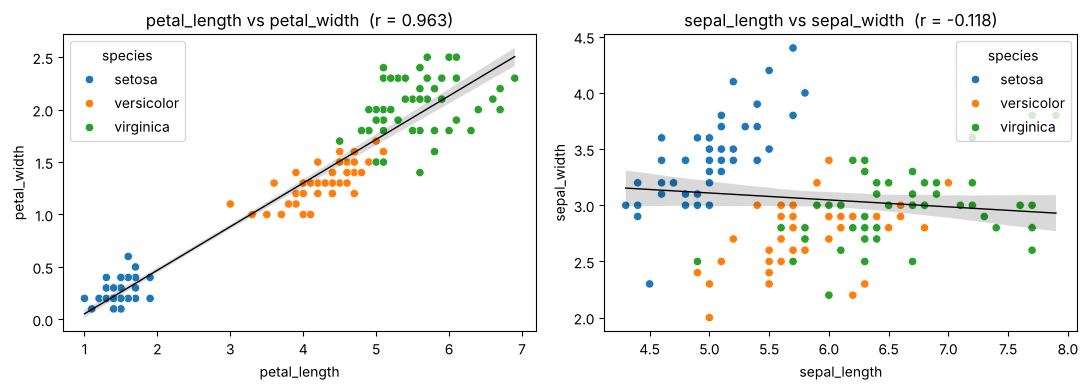

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (a, b) in zip(axes, [("petal_length", "petal_width"), ("sepal_length", "sepal_width")]):
    sns.scatterplot(data=df, x=a, y=b, hue="species", ax=ax)
    sns.regplot(data=df, x=a, y=b, scatter=False, ax=ax, color="black", line_kws={"lw": 1})
    ax.set_title(f"{a} vs {b}  (r = {df[a].corr(df[b]):.3f})")
plt.tight_layout()
plt.show()

**Observation**
* petal_length vs petal_width : r ≈ 0.96, a very strong positive linear relation.
* sepal_length vs sepal_width : r ≈ -0.12, a weak negative relation, almost no linear link across the whole dataset.

### B2 : Covariance matrix

In [8]:
num = df.drop(columns="species")

# manual : (1 / (n-1)) * Xcᵀ Xc  where Xc is the mean-centred data
Xc = num.values - num.values.mean(axis=0)
cov_matrix_manual = (Xc.T @ Xc) / (len(num) - 1)

cov_matrix = num.cov()          # pandas
print("Manual equals pandas :", np.allclose(cov_matrix_manual, cov_matrix.values))
cov_matrix

Manual equals pandas : True


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,0.6857,-0.0424,1.2743,0.5163
sepal_width,-0.0424,0.1900,-0.3297,-0.1216
petal_length,1.2743,-0.3297,3.1163,1.2956
petal_width,0.5163,-0.1216,1.2956,0.5810


### B3 : Correlation matrix

In [9]:
# manual : divide each covariance by the product of the two standard deviations
std = np.sqrt(np.diag(cov_matrix_manual))
corr_matrix_manual = cov_matrix_manual / np.outer(std, std)

corr_matrix = num.corr()        # pandas (Pearson)
print("Manual equals pandas :", np.allclose(corr_matrix_manual, corr_matrix.values))
corr_matrix

Manual equals pandas : True


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.0000,-0.1176,0.8718,0.8179
sepal_width,-0.1176,1.0000,-0.4284,-0.3661
petal_length,0.8718,-0.4284,1.0000,0.9629
petal_width,0.8179,-0.3661,0.9629,1.0000


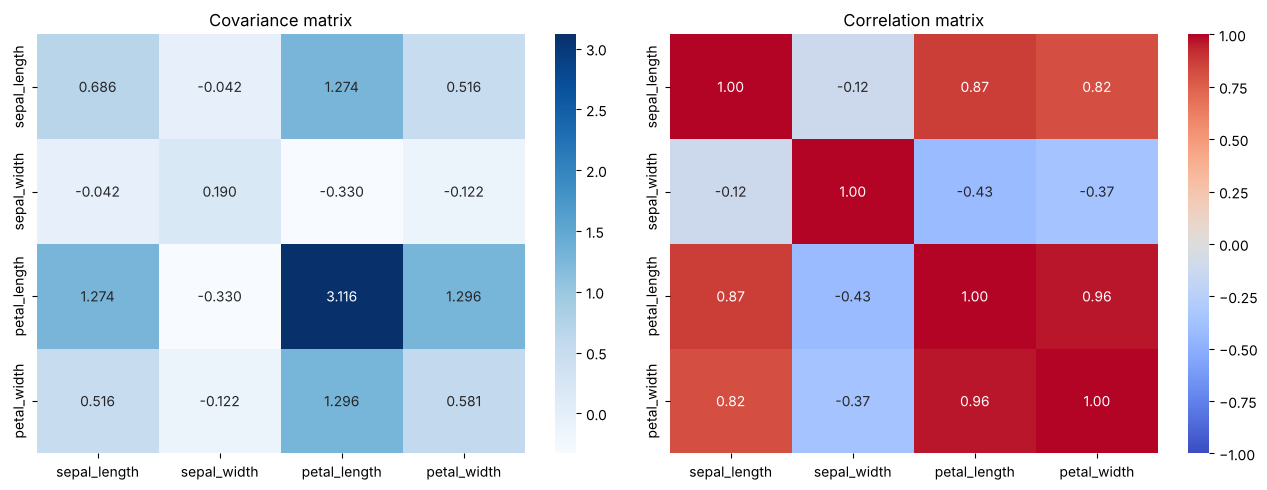

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cov_matrix, annot=True, fmt=".3f", cmap="Blues", ax=axes[0])
axes[0].set_title("Covariance matrix")
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlation matrix")
plt.tight_layout()
plt.show()

## Result & Conclusion
* Covariance and correlation for a pair of attributes and the full covariance and correlation matrices of Iris were computed manually and with NumPy/pandas; both methods give identical results.
* The covariance matrix's diagonal holds the variances (petal_length has the largest spread). Its values depend on units, so they are hard to compare.
* The correlation matrix is unit-free : petal_length, petal_width and sepal_length are all strongly positively correlated (r > 0.8), while sepal_width is weakly negatively correlated with the others.
* Highly correlated attributes carry overlapping information, which is exactly what PCA (next program) exploits to reduce dimensions.